In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

In [2]:
# Load dataset
file_path = '/content/dataset-pinjaman-nasabah.csv'
data = pd.read_csv(file_path)

In [3]:
# Display initial dataset
print("Initial Dataset:")
print(data.head())

Initial Dataset:
  ID_Nasabah JenisKelamin StatusPernikahan  JumTanggungan    Pendidikan  \
0   LP001002         Male               No            0.0      Graduate   
1   LP001003         Male              Yes            1.0      Graduate   
2   LP001005         Male              Yes            0.0      Graduate   
3   LP001006         Male              Yes            0.0  Not Graduate   
4   LP001008         Male               No            0.0      Graduate   

  Wiraswasta  IncomeNasabah  IncomePasangan  JumlahPinjaman  \
0         No           5849               0             NaN   
1         No           4583            1508           128.0   
2        Yes           3000               0            66.0   
3         No           2583            2358           120.0   
4         No           6000               0           141.0   

   JangkaWaktuPinjaman  Credit_History WilayahTempatTinggal StatusPinjaman  
0                360.0             1.0                Urban              Y  

In [4]:
# Check missing values
print("\nMissing Values Before Handling:")
print(data.isnull().sum())


Missing Values Before Handling:
ID_Nasabah               0
JenisKelamin            13
StatusPernikahan         3
JumTanggungan           15
Pendidikan               0
Wiraswasta              32
IncomeNasabah            0
IncomePasangan           0
JumlahPinjaman          22
JangkaWaktuPinjaman     14
Credit_History          50
WilayahTempatTinggal     0
StatusPinjaman           0
dtype: int64


In [5]:
# Handle missing values
imputer_mean = SimpleImputer(strategy='mean')
imputer_most_frequent = SimpleImputer(strategy='most_frequent')

In [6]:
# Numeric columns
numeric_cols = ['JumTanggungan', 'JumlahPinjaman', 'JangkaWaktuPinjaman', 'Credit_History']
data[numeric_cols] = imputer_mean.fit_transform(data[numeric_cols])

In [7]:
# Categorical columns
categorical_cols = ['JenisKelamin', 'StatusPernikahan', 'Wiraswasta']
data[categorical_cols] = imputer_most_frequent.fit_transform(data[categorical_cols])

In [8]:
# Check missing values after handling
print("\nMissing Values After Handling:")
print(data.isnull().sum())


Missing Values After Handling:
ID_Nasabah              0
JenisKelamin            0
StatusPernikahan        0
JumTanggungan           0
Pendidikan              0
Wiraswasta              0
IncomeNasabah           0
IncomePasangan          0
JumlahPinjaman          0
JangkaWaktuPinjaman     0
Credit_History          0
WilayahTempatTinggal    0
StatusPinjaman          0
dtype: int64


In [9]:
# Encode categorical variables
encoder = LabelEncoder()
encoded_cols = ['JenisKelamin', 'StatusPernikahan', 'Pendidikan', 'Wiraswasta', 'WilayahTempatTinggal', 'StatusPinjaman']
for col in encoded_cols:
    data[col] = encoder.fit_transform(data[col])

In [10]:
# Map target variable (Layak = 0, Tidak Layak = 1)
data['StatusPinjaman'] = data['StatusPinjaman'].map({0: 1, 1: 0})

In [11]:
# Display dataset after preprocessing
print("\nDataset After Preprocessing:")
print(data.head())


Dataset After Preprocessing:
  ID_Nasabah  JenisKelamin  StatusPernikahan  JumTanggungan  Pendidikan  \
0   LP001002             1                 0            0.0           0   
1   LP001003             1                 1            1.0           0   
2   LP001005             1                 1            0.0           0   
3   LP001006             1                 1            0.0           1   
4   LP001008             1                 0            0.0           0   

   Wiraswasta  IncomeNasabah  IncomePasangan  JumlahPinjaman  \
0           0           5849               0      146.412162   
1           0           4583            1508      128.000000   
2           1           3000               0       66.000000   
3           0           2583            2358      120.000000   
4           0           6000               0      141.000000   

   JangkaWaktuPinjaman  Credit_History  WilayahTempatTinggal  StatusPinjaman  
0                360.0             1.0                 

In [12]:
# Features and target
X = data.drop(columns=['ID_Nasabah', 'StatusPinjaman'])
y = data['StatusPinjaman']

In [13]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# Display split data sizes
print("\nData Split:")
print(f"Training Data: {X_train.shape[0]} samples")
print(f"Testing Data: {X_test.shape[0]} samples")


Data Split:
Training Data: 491 samples
Testing Data: 123 samples


In [15]:
# Train a Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [16]:
# Make predictions
y_pred = model.predict(X_test)

Confusion Matrix:
[[77  3]
 [25 18]]


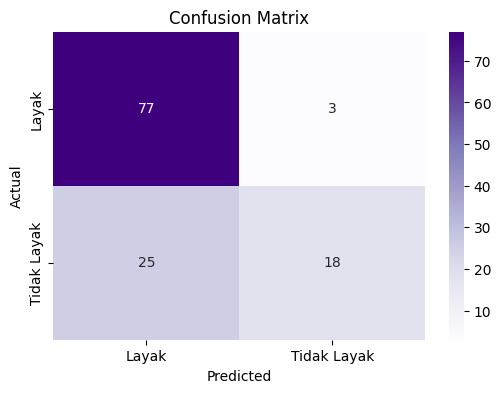

Akurasi Model: 0.77

Laporan Klasifikasi:
              precision    recall  f1-score   support

       Layak       0.75      0.96      0.85        80
 Tidak Layak       0.86      0.42      0.56        43

    accuracy                           0.77       123
   macro avg       0.81      0.69      0.70       123
weighted avg       0.79      0.77      0.75       123



In [17]:
# Evaluasi model
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=['Layak', 'Tidak Layak'], yticklabels=['Layak', 'Tidak Layak'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# b) Akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy:.2f}")

# c) Laporan Klasifikasi
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=['Layak', 'Tidak Layak']))

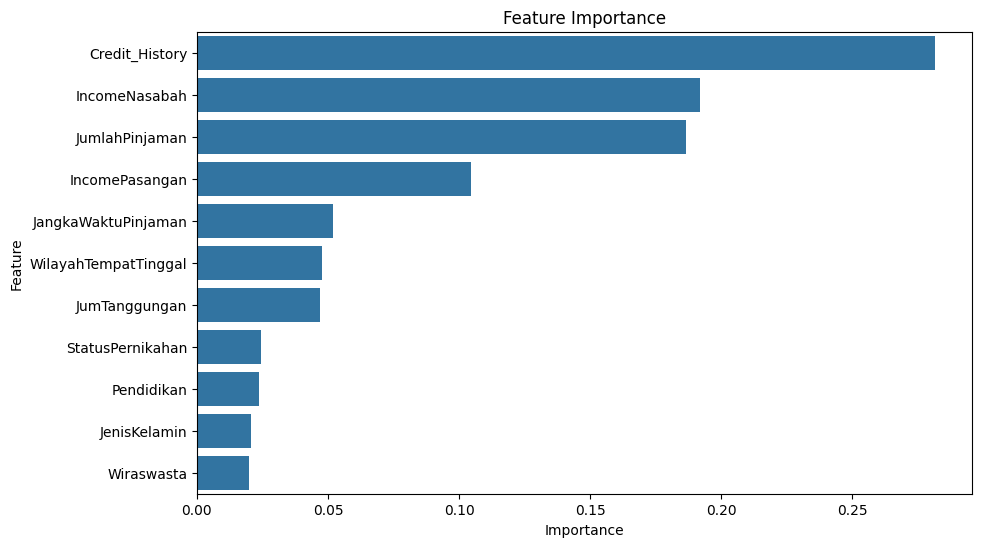

In [18]:
# Feature importance
feature_importances = model.feature_importances_
importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': feature_importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importance')
plt.show()

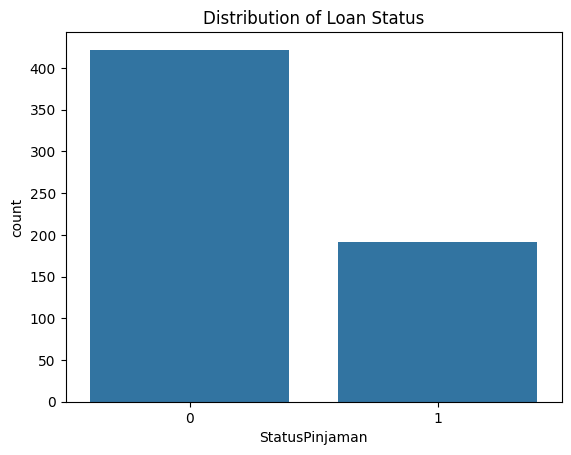

In [19]:
# Distribution of target variable
sns.countplot(x='StatusPinjaman', data=data)
plt.title('Distribution of Loan Status')
plt.show()

In [20]:
# Display eligible and ineligible customers based on income threshold
income_threshold = 5000
eligible = data[(data['StatusPinjaman'] == 0) & (data['IncomeNasabah'] >= income_threshold)]
ineligible = data[(data['StatusPinjaman'] == 1) & (data['IncomeNasabah'] <= income_threshold)]

print("\nEligible Customers Based on Income:")
print(eligible[['ID_Nasabah', 'IncomeNasabah', 'StatusPinjaman']])

print("\nIneligible Customers Based on Income:")
print(ineligible[['ID_Nasabah', 'IncomeNasabah', 'StatusPinjaman']])


Eligible Customers Based on Income:
    ID_Nasabah  IncomeNasabah  StatusPinjaman
0     LP001002           5849               0
4     LP001008           6000               0
5     LP001011           5417               0
21    LP001046           5955               0
25    LP001066           9560               0
..         ...            ...             ...
599   LP002948           5780               0
602   LP002953           5703               0
604   LP002959          12000               0
611   LP002983           8072               0
612   LP002984           7583               0

[134 rows x 3 columns]

Ineligible Customers Based on Income:
    ID_Nasabah  IncomeNasabah  StatusPinjaman
1     LP001003           4583               1
7     LP001014           3036               1
13    LP001029           1853               1
17    LP001036           3510               1
18    LP001038           4887               1
..         ...            ...             ...
589   LP002926           2

In [21]:
# Ubah kolom StatusPinjaman untuk merepresentasikan kelayakan
eligible['StatusPinjaman'] = 0  # Layak
ineligible['StatusPinjaman'] = 1  # Tidak Layak

# Gabungkan kedua dataframe
combined_data = pd.concat([eligible, ineligible])

# Sortir berdasarkan kolom ID_Nasabah agar urutan rapi
combined_data = combined_data.sort_values(by='ID_Nasabah')

# Pilih kolom yang ingin disimpan
combined_data = combined_data[['ID_Nasabah', 'JenisKelamin' , 'StatusPernikahan' ,'JumTanggungan' ,'Pendidikan' , 'Wiraswasta' , 'IncomeNasabah' , 'IncomePasangan' , 'JumlahPinjaman' ,'JangkaWaktuPinjaman' ,'Credit_History', 'WilayahTempatTinggal' ,'StatusPinjaman']]

# Simpan ke file CSV
combined_data.to_csv('combined_customers_sorted.csv', index=False)

print("File CSV gabungan telah disimpan sebagai 'combined_customers_sorted.csv'")


File CSV gabungan telah disimpan sebagai 'combined_customers_sorted.csv'


<ipython-input-21-037b0164dd22>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  eligible['StatusPinjaman'] = 0  # Layak
<ipython-input-21-037b0164dd22>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ineligible['StatusPinjaman'] = 1  # Tidak Layak


In [22]:
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Memuat dataset dari file
file_path = 'dataset-pinjaman-nasabah.csv'
data = pd.read_csv(file_path)

# Menampilkan beberapa baris pertama dataset
print("Contoh Data:")
print(data.head())

# Mengatur variabel fitur (X) dan target (y)
# Menghapus kolom 'ID_Nasabah' dan 'StatusPinjaman' dari fitur (X)
X = data.drop(columns=['ID_Nasabah', 'StatusPinjaman'])
y = data['StatusPinjaman']

# Encoding target jika diperlukan
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# ----> Perform Label Encoding on categorical features in X
categorical_cols = ['JenisKelamin', 'StatusPernikahan', 'Pendidikan', 'Wiraswasta', 'WilayahTempatTinggal']
for col in categorical_cols:
    le = LabelEncoder() # Create a new LabelEncoder for each column
    X[col] = le.fit_transform(X[col]) # Fit and transform on the column in X

# Inisialisasi model
model = RandomForestClassifier(random_state=42)

# Membuat K-Fold Cross Validation
k = 5  # Jumlah fold
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Evaluasi model menggunakan cross-validation
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')

# Tampilkan hasil evaluasi
print(f"Hasil Akurasi pada {k}-Fold Cross Validation:")
for i, score in enumerate(scores):
    print(f"Fold {i+1}: Akurasi = {score:.2f}")

print(f"\nRata-rata Akurasi: {scores.mean():.2f}")

Contoh Data:
  ID_Nasabah JenisKelamin StatusPernikahan  JumTanggungan    Pendidikan  \
0   LP001002         Male               No            0.0      Graduate   
1   LP001003         Male              Yes            1.0      Graduate   
2   LP001005         Male              Yes            0.0      Graduate   
3   LP001006         Male              Yes            0.0  Not Graduate   
4   LP001008         Male               No            0.0      Graduate   

  Wiraswasta  IncomeNasabah  IncomePasangan  JumlahPinjaman  \
0         No           5849               0             NaN   
1         No           4583            1508           128.0   
2        Yes           3000               0            66.0   
3         No           2583            2358           120.0   
4         No           6000               0           141.0   

   JangkaWaktuPinjaman  Credit_History WilayahTempatTinggal StatusPinjaman  
0                360.0             1.0                Urban              Y  
1  

Fold 1: Akurasi = 0.76
Fold 2: Akurasi = 0.80
Fold 3: Akurasi = 0.80

Confusion Matrix pada Fold ke-3:
[[17 17]
 [ 7 82]]


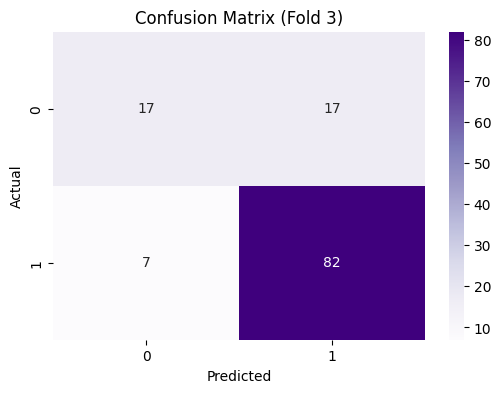

              precision    recall  f1-score   support

           0       0.71      0.50      0.59        34
           1       0.83      0.92      0.87        89

    accuracy                           0.80       123
   macro avg       0.77      0.71      0.73       123
weighted avg       0.80      0.80      0.79       123

Fold 4: Akurasi = 0.77
Fold 5: Akurasi = 0.80


In [23]:
k = 5  # Jumlah fold
kf = KFold(n_splits=k, shuffle=True, random_state=42)

label_encoder = LabelEncoder()

label_encoder.fit(y)

fold = 1
best_fold = 3  # Menampilkan Confusion Matrix untuk Fold ke-3

for train_index, test_index in kf.split(X):
    # Split data menjadi training dan testing set
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Latih model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluasi akurasi untuk setiap fold
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Fold {fold}: Akurasi = {accuracy:.2f}")

    # Simpan dan tampilkan Confusion Matrix untuk fold ke-3
    if fold == best_fold:
        print(f"\nConfusion Matrix pada Fold ke-{best_fold}:")
        cm = confusion_matrix(y_test, y_pred)
        print(cm)

        # Visualisasi Confusion Matrix
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                    xticklabels=label_encoder.classes_, # Now label_encoder is defined
                    yticklabels=label_encoder.classes_) # Now label_encoder is defined
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix (Fold {best_fold})")
        plt.show()

        # Tampilkan laporan klasifikasi
       # Convert label_encoder.classes_ to a list of strings
        target_names = [str(cls) for cls in label_encoder.classes_]
        print(classification_report(y_test, y_pred, target_names=target_names))

    fold += 1